In [1]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm

from cmfa.emu_example import ordered_ilr_func


In [2]:
RESULTS_DIR = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [3]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy", allow_pickle=True).item()
true_id = np.load(RESULTS_DIR / "true_composition.npy", allow_pickle=True).item()
print(f"True flux: {true_flux}")
print(f"True isotopologue distribution: {true_id}")

True flux: {'v8': Array(0.215, dtype=float64), 'v1': Array(1., dtype=float64), 'v19': Array(0.05, dtype=float64), 'v20': Array(0.03, dtype=float64), 'v16': Array(0.07, dtype=float64), 'v17': Array(0.23, dtype=float64), 'v18': Array(0.12, dtype=float64), 'v2': Array(0.201, dtype=float64), 'v9': Array(0.296, dtype=float64), 'v3': Array(0.621, dtype=float64), 'v4': Array(0.621, dtype=float64), 'v5': Array(0.621, dtype=float64), 'v6': Array(0.592, dtype=float64), 'v11': Array(1.213, dtype=float64), 'v12': Array(0.296, dtype=float64), 'v13': Array(1.509, dtype=float64), 'v14': Array(1.735, dtype=float64), 'v15': Array(5.561, dtype=float64), 'v10': Array(0.475, dtype=float64), 'v7': Array(0.807, dtype=float64)}
True isotopologue distribution: {'lysx_123456': Array([0.01567147, 0.11709665, 0.24642148, 0.28673379, 0.21348085,
       0.10003428, 0.02056148], dtype=float64), 'valx_12345': Array([0.0128301 , 0.10251097, 0.27570439, 0.34531928, 0.21147698,
       0.05215829], dtype=float64), 'aspx

# Reference 

In [4]:
with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)

In [5]:
with open(RESULTS_DIR / "estimated_fluxes_ci_reference.pkl", "rb") as f:
    flux_ci_ref = pickle.load(f)

In [6]:
with open(RESULTS_DIR / "estimated_ids_reference.pkl", "rb") as f:
    estimated_ids_ref = pickle.load(f)

In [7]:
estimated_fluxes_ref["trad"].shape

(1000, 3)

In [8]:
true_ref = np.array([true_flux[k] for k in ["v8", "v2", "v9"]])

resid_trad = estimated_fluxes_ref["trad"][:,:] - true_ref[None, :]
resid_clr = estimated_fluxes_ref["clr"][:,:] - true_ref[None, :]
resid_ilr = estimated_fluxes_ref["ilr"][:,:] - true_ref[None, :]

mse_trad = (resid_trad ** 2).mean(axis=(0))
mse_clr = (resid_clr ** 2).mean(axis=(0))
mse_ilr = (resid_ilr ** 2).mean(axis=(0))

mse_trad, mse_clr, mse_ilr

(Array([0.04173926, 0.00014042, 0.00660106], dtype=float64),
 Array([1.59893227e-02, 5.79966093e-05, 1.75841281e-03], dtype=float64),
 Array([1.59500466e-02, 5.78906182e-05, 1.75847521e-03], dtype=float64))

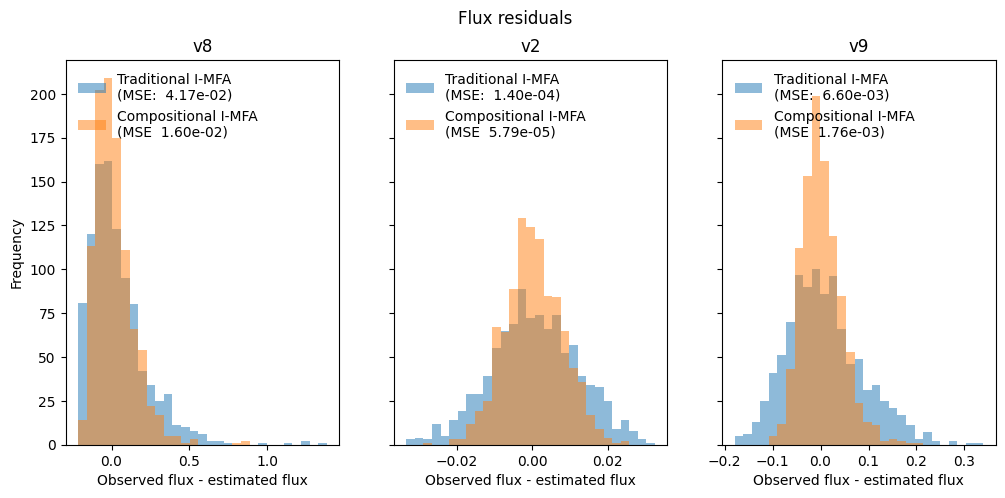

In [9]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, i].flatten()
    resid_comp_i = resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_tca.png", bbox_inches="tight", dpi=200)

In [10]:
estimated_fluxes_ref["trad"]

Array([[0.19018952, 0.19053813, 0.28365414],
       [0.44220403, 0.20656895, 0.32031227],
       [0.0214741 , 0.19108805, 0.3323692 ],
       ...,
       [0.34137304, 0.20227259, 0.2907475 ],
       [0.07515269, 0.21393044, 0.42319751],
       [0.05167688, 0.19581736, 0.30212022]], dtype=float64)

In [11]:
flux_ci_trad_ref = jnp.exp(jnp.log(flux_ci_ref["trad"][:,:,:]).mean(axis=0))
flux_ci_ilr_ref = jnp.exp(jnp.log(flux_ci_ref["ilr"][:,:,:]).mean(axis=0))

In [35]:
flux_ci_trad_ref = flux_ci_ref["trad"][364,:,:]
flux_ci_ilr_ref = flux_ci_ref["ilr"][364,:,:]

In [12]:
max(flux_ci_ref["ilr"][:,0,0])

Array(0.1252304, dtype=float64)

In [36]:
flux = list(true_flux.keys())
print(f"{'Traditional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_trad_ref):
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

               Traditional                
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v8     |          0.0000 |      15891.5967
v1     |          1.0000 |          1.0000
v19    |          0.0500 |          0.0500
v20    |          0.0300 |          0.0300
v16    |          0.0700 |          0.0700
v17    |          0.2300 |          0.2300
v18    |          0.1200 |          0.1200
v2     |          0.1185 |          0.4034
v9     |          0.0539 |          8.1597
v3     |          0.3462 |          1.1783
v4     |          0.3462 |          1.1783
v5     |          0.3462 |          1.1783
v6     |          0.1843 |          2.1353
v11    |          0.2016 |          7.9504
v12    |          0.1700 |          0.5787
v13    |          0.1363 |         18.3023
v14    |          0.0853 |         38.9756
v15    |          0.0006 |      49611.8113
v10    |          0.0921 |          7.3858
v7     |          0.0000 |     342246.3861


In [37]:
print(f"{'Compositional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_ilr_ref):
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

              Compositional               
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v8     |          0.0171 |          1.6002
v1     |          1.0000 |          1.0000
v19    |          0.0500 |          0.0500
v20    |          0.0300 |          0.0300
v16    |          0.0700 |          0.0700
v17    |          0.2300 |          0.2300
v18    |          0.1200 |          0.1200
v2     |          0.1777 |          0.2469
v9     |          0.2296 |          0.8670
v3     |          0.5340 |          0.7420
v4     |          0.5340 |          0.7420
v5     |          0.5340 |          0.7420
v6     |          0.4382 |          0.8461
v11    |          0.7560 |          2.0285
v12    |          0.2583 |          0.3589
v13    |          0.7990 |          2.9791
v14    |          0.7808 |          4.0454
v15    |          0.3912 |         78.8790
v10    |          0.3286 |          1.1577
v7     |          0.0695 |          8.6244


In [40]:
v8_trad = flux_ci_ref["trad"][:,0,:]
v2_trad = flux_ci_ref["trad"][:,7,:]
v9_trad = flux_ci_ref["trad"][:,8,:]

v8_ilr = flux_ci_ref["ilr"][:,0,:]
v2_ilr = flux_ci_ref["ilr"][:,7,:]
v9_ilr  = flux_ci_ref["ilr"][:,8,:]

In [ ]:
sum((v8_ilr[:,1])>10)

Array(0, dtype=int64, weak_type=True)

In [58]:
sum((v8_trad[:,1])>10)

Array(1000, dtype=int64, weak_type=True)

In [64]:
sum((v8_ilr[:,0])<1e-2)

Array(188, dtype=int64, weak_type=True)

In [66]:
sum((v8_trad[:,0])<1e-2)

Array(1000, dtype=int64, weak_type=True)

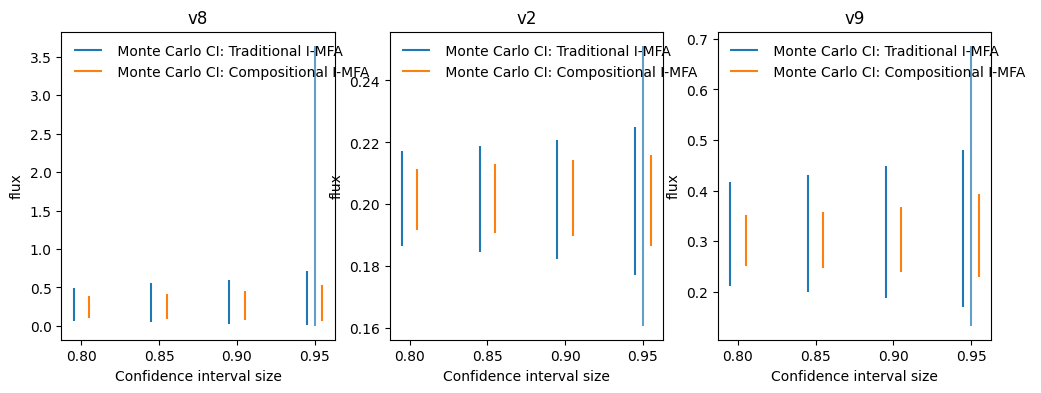

In [75]:
def get_ci_bounds(ci_size):
    low = (1.0 - ci_size) / 2
    high = 1.0 - low
    return low, high


with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    mc_estimated_fluxes = pickle.load(f)

N_BOUND = 4

plot_df_rows = []
ci_sizes = np.linspace(0.80, 0.95, N_BOUND)
for i, ci_size in enumerate(ci_sizes):
    row = {"ci_size": ci_size}
    qlow, qhigh = get_ci_bounds(ci_size)
    for model in ("trad", "ilr"):
        row[f"{model}_low_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qlow, axis=0)
        row[f"{model}_low_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qlow, axis=0)
        row[f"{model}_low_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qlow, axis=0)
        row[f"{model}_high_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qhigh, axis=0)
        row[f"{model}_high_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qhigh, axis=0)
        row[f"{model}_high_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qhigh, axis=0)
    plot_df_rows.append(row)

plot_df = pl.DataFrame(plot_df_rows)
f, axes = plt.subplots(1, 3, figsize=[12, 4])
axes = axes.ravel()
for ax, flux_ix in zip(axes, (0, 1, 2)):
    for offset, model, color in zip((-0.005, 0.005), ("trad", "ilr"), ("tab:blue", "tab:orange")):
        ax.vlines(
            plot_df["ci_size"] + offset, 
            plot_df[f"{model}_low_{flux_ix}"], 
            plot_df[f"{model}_high_{flux_ix}"], 
            color=color,
            label=" Monte Carlo CI: " + model.replace("ilr", "Compositional I-MFA").replace("trad", "Traditional I-MFA")
        )
    # ax.axhline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]: .2f})")
    ax.set(xlabel="Confidence interval size", ylabel="flux", title=f"v{free_flux_numbers[flux_ix]}")
    ax.legend(frameon=False, loc="upper left")
x_pos = np.full((1000, 1), 0.95)
axes[0].vlines(x=0.95,  ymin=np.quantile(v8_ilr[:,0],0.05), ymax = np.quantile(v8_ilr[:,1],0.95), alpha=0.7)
axes[1].vlines(x=0.95,  ymin=np.quantile(v2_ilr[:,0],0.05), ymax = np.quantile(v2_ilr[:,1],0.95), alpha=0.7)
axes[2].vlines(x=0.95,  ymin=np.quantile(v9_ilr[:,0],0.05), ymax = np.quantile(v9_ilr[:,1],0.95), alpha=0.7)
# axes[1].vlines(x=x_pos,  ymin=v2_ilr[:,0], ymax = v2_ilr[:,1], alpha=0.1)
# axes[2].vlines(x=x_pos,  ymin=v9_ilr[:,0], ymax = v9_ilr[:,1], alpha=0.1)

plt.show()

# Sensitivity

In [16]:
free_fluxes = jnp.load(RESULTS_DIR / "free_fluxes.npy", allow_pickle=True)
free_fluxes.shape

(125, 3)

In [17]:
target = np.array([[true_flux['v8'], true_flux['v2'], true_flux['v9']]])
true_flux_index= np.where(np.isclose(free_fluxes,target).all(axis=1))[0].item()
free_fluxes[true_flux_index]

Array([0.215, 0.201, 0.296], dtype=float64)

In [18]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements.npy", allow_pickle=True)
type(intensity_msts)

list

In [19]:
true_ids = jnp.load(RESULTS_DIR / "true_isotopologue_distributions.npy", allow_pickle=True)
type(true_ids)

list

In [20]:
with open(RESULTS_DIR / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes = pickle.load(f)

In [21]:
with open(RESULTS_DIR / "estimated_ids.pkl", "rb") as f:
    estimated_ids = pickle.load(f)

In [22]:
estimated_fluxes["trad"].shape

(125, 50, 3)

In [23]:
resid_trad = (free_fluxes[:, None, :] - estimated_fluxes["trad"][:, :, :])/free_fluxes[:, None, :]
resid_clr = (free_fluxes[:, None, :] - estimated_fluxes["clr"][:, :, :])/free_fluxes[:, None, :]
resid_ilr = (free_fluxes[:, None, :] - estimated_fluxes["ilr"][:, :, :])/free_fluxes[:, None, :]

mse_trad = (resid_trad ** 2).mean(axis=(0, 1))
mse_clr = (resid_clr ** 2).mean(axis=(0, 1))
mse_ilr = (resid_ilr ** 2).mean(axis=(0, 1))

mse_trad, mse_clr, mse_ilr

(Array([1.82881475, 0.0046557 , 0.08802448], dtype=float64),
 Array([0.35728181, 0.00159864, 0.02033965], dtype=float64),
 Array([0.35621251, 0.00160606, 0.02040895], dtype=float64))

In [24]:
id_resid_trad = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["trad"])
]
id_resid_clr = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["clr"])
]
id_resid_ilr = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["ilr"])
]

n_elements = len(id_resid_trad) * len(id_resid_trad[0])

id_mse_trad = {
    k: sum(row[col][k]**2 for row in id_resid_trad for col in range(len(row))) / n_elements
    for k in true_ids[0]
}
id_mse_clr = {
    k: sum(row[col][k]**2 for row in id_resid_clr for col in range(len(row))) / n_elements
    for k in true_ids[0]
}
id_mse_ilr = {
    k: sum(row[col][k]**2 for row in id_resid_ilr for col in range(len(row))) / n_elements
    for k in true_ids[0]
}


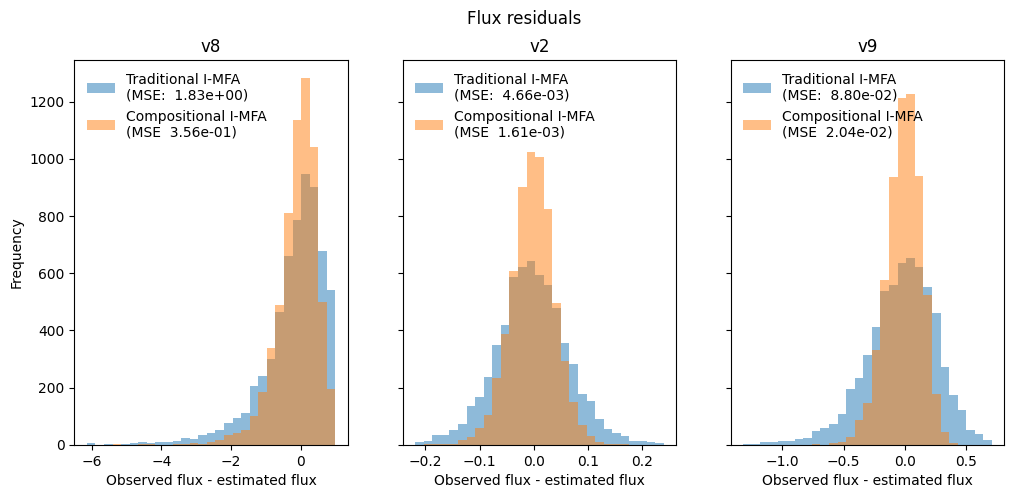

In [25]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()
    resid_comp_i = resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy.png", bbox_inches="tight", dpi=200)

In [26]:
id_resid_trad_lysx = jnp.array([
    id_resid_trad[i][j]["lysx_123456"] 
    for i in range(len(free_fluxes)) 
    for j in range(50)
])

id_resid_ilr_lysx = jnp.array([
    id_resid_ilr[i][j]["lysx_123456"] 
    for i in range(len(free_fluxes)) 
    for j in range(50)
])

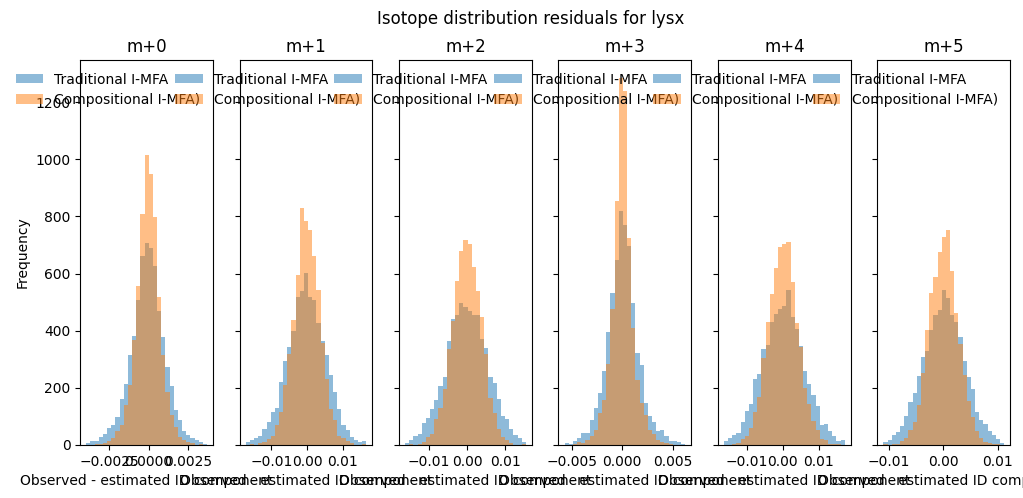

In [27]:
f, axes = plt.subplots(1, 6, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad_lysx[:, i].flatten()
    resid_comp_i = id_resid_ilr_lysx[:, i].flatten()
    xmin = np.quantile(resid_trad_i, 0.001)
    xmax = np.quantile(resid_trad_i, 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA)" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"m+{i}", xlabel="Observed - estimated ID component")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Isotope distribution residuals for lysx");

In [28]:
with open(RESULTS_DIR / "entropies.npy", "rb") as f:
    entropies = pickle.load(f)
len(entropies)

125

In [29]:
entropies_max = [max(idx.values()) for idx in entropies]
diff_flux = ((resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1))
# /(resid_trad ** 2).mean(axis=1)

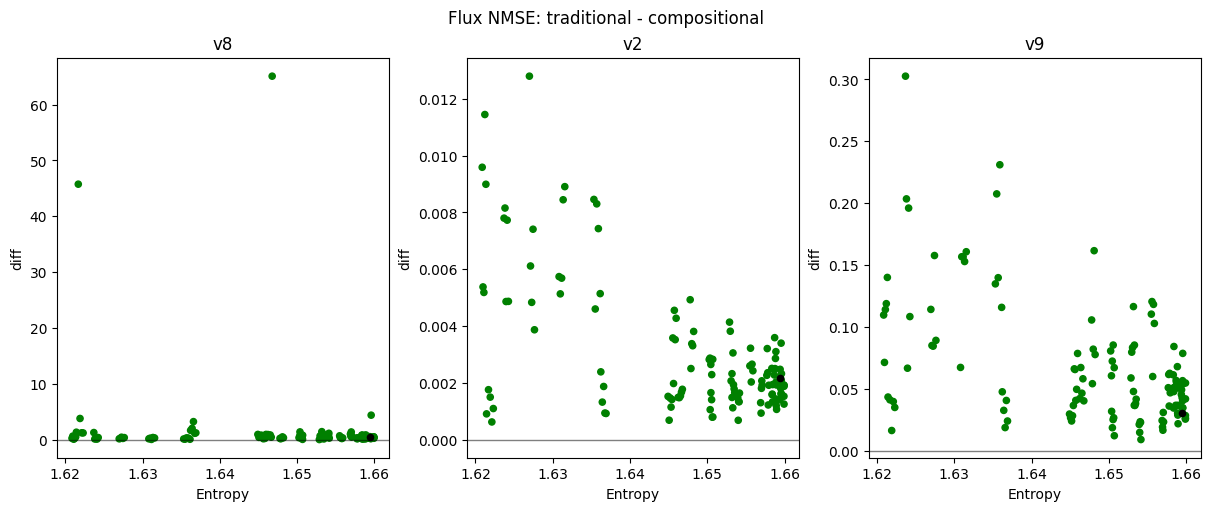

In [30]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], layout= "constrained")
axes = axes.ravel()
point_size=20
for i in range(3):
    y_values = diff_flux[:,i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies_max, y_values, c=colors, s=point_size)
    axes[i].scatter(entropies_max[true_flux_index], y_values[true_flux_index], color="black", s=point_size)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5, label="Reference flux")
    axes[i].set(xlabel="Entropy", ylabel="diff", title=f"v{free_flux_numbers[i]}")
f.suptitle("Flux NMSE: traditional - compositional")

plt.show()

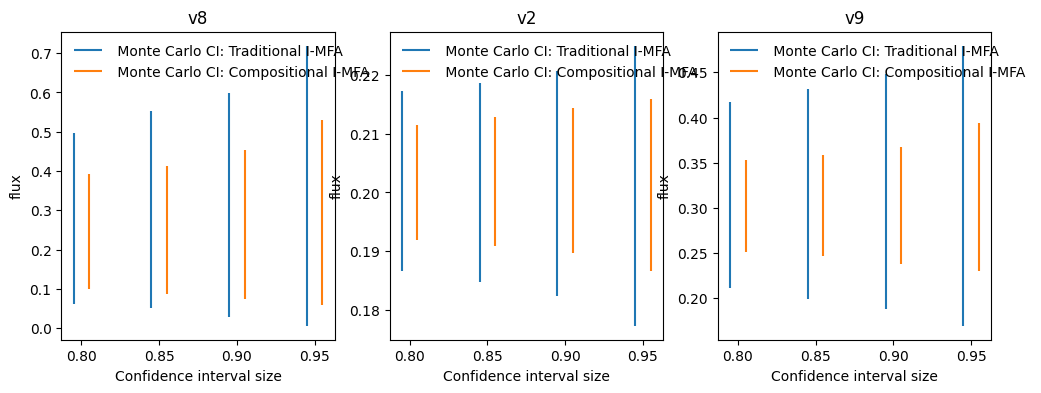

In [31]:
def get_ci_bounds(ci_size):
    low = (1.0 - ci_size) / 2
    high = 1.0 - low
    return low, high


with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    mc_estimated_fluxes = pickle.load(f)

N_BOUND = 4

plot_df_rows = []
ci_sizes = np.linspace(0.80, 0.95, N_BOUND)
for i, ci_size in enumerate(ci_sizes):
    row = {"ci_size": ci_size}
    qlow, qhigh = get_ci_bounds(ci_size)
    for model in ("trad", "ilr"):
        row[f"{model}_low_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qlow, axis=0)
        row[f"{model}_low_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qlow, axis=0)
        row[f"{model}_low_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qlow, axis=0)
        row[f"{model}_high_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qhigh, axis=0)
        row[f"{model}_high_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qhigh, axis=0)
        row[f"{model}_high_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qhigh, axis=0)
    plot_df_rows.append(row)


plot_df = pl.DataFrame(plot_df_rows)
f, axes = plt.subplots(1, 3, figsize=[12, 4])
axes = axes.ravel()
for ax, flux_ix in zip(axes, (0, 1, 2)):
    for offset, model, color in zip((-0.005, 0.005), ("trad", "ilr"), ("tab:blue", "tab:orange")):
        ax.vlines(
            plot_df["ci_size"] + offset, 
            plot_df[f"{model}_low_{flux_ix}"], 
            plot_df[f"{model}_high_{flux_ix}"], 
            color=color,
            label=" Monte Carlo CI: " + model.replace("ilr", "Compositional I-MFA").replace("trad", "Traditional I-MFA")
        )
    # ax.axhline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]: .2f})")
    ax.set(xlabel="Confidence interval size", ylabel="flux", title=f"v{free_flux_numbers[flux_ix]}")
    ax.legend(frameon=False, loc="upper left")